# TP SIEVE — 8 modèles NLP sur `output_0`

Modèles : Simple RNN, GRU, Peephole LSTM, Tiny LSTM, DistilGPT-2, GPT-1, DistilBERT et TinyBERT.


## 1. Imports, appareil et paramètres

In [3]:
import re, time, copy, gc, random
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", DEVICE)

RAW_FILE = Path("data/output_0.log")
DATA_DIR = Path("processed_data")

TRAIN_FILE = DATA_DIR / "output_0_X_train.csv"
VAL_FILE = DATA_DIR / "output_0_X_val.csv"
TEST_FILE = DATA_DIR / "output_0_X_test.csv"

Y_TRAIN_FILE = DATA_DIR / "output_0_y_train.csv"
Y_VAL_FILE   = DATA_DIR / "output_0_y_val.csv"
Y_TEST_FILE  = DATA_DIR / "output_0_y_test.csv"

RESULTS_DIR, MODELS_DIR = Path("results"), Path("models")
RESULTS_DIR.mkdir(exist_ok=True); MODELS_DIR.mkdir(exist_ok=True)

MAX_LEN = 128
MAX_VOCAB = 30000
BATCH_RNN = 128
BATCH_HF = 8       
EPOCHS_RNN = 8
EPOCHS_HF = 3
EMBED_DIM, HIDDEN_DIM = 128, 128
LR_RNN, LR_HF = 1e-3, 2e-5


Appareil : mps


## 2. Chargement des données

In [4]:

def standardize_X(df):
    """Récupère et normalise la colonne contenant les logs."""
    cols = {str(c).strip().lower(): c for c in df.columns}
    text_col = next(
        (cols[k] for k in ("log", "text", "message") if k in cols),
        None
    )

    # Si le fichier X ne contient qu'une seule colonne,
    # on considère que cette colonne contient les logs.
    if text_col is None and len(df.columns) == 1:
        text_col = df.columns[0]

    if text_col is None:
        raise ValueError(
            f"Colonne log/text/message introuvable. "
            f"Colonnes reçues : {list(df.columns)}"
        )

    out = df[[text_col]].copy()
    out.columns = ["text"]
    out["text"] = out["text"].fillna("").astype(str)
    return out


def standardize_y(df):
    """Récupère et normalise la colonne contenant les labels."""
    cols = {str(c).strip().lower(): c for c in df.columns}
    label_col = next(
        (cols[k] for k in ("label", "category", "class", "y") if k in cols),
        None
    )

    # Si le fichier y ne contient qu'une seule colonne,
    # on considère que cette colonne contient les labels.
    if label_col is None and len(df.columns) == 1:
        label_col = df.columns[0]

    if label_col is None:
        raise ValueError(
            f"Colonne label/category/class introuvable. "
            f"Colonnes reçues : {list(df.columns)}"
        )

    out = df[[label_col]].copy()
    out.columns = ["label"]
    out["label"] = out["label"].astype(str)
    return out


def load_partition(x_file, y_file):
    """Charge X et y puis les associe."""
    X = standardize_X(pd.read_csv(x_file))
    y = standardize_y(pd.read_csv(y_file))

    if len(X) != len(y):
        raise ValueError(
            f"Nombre de logs différent du nombre de labels : "
            f"{x_file.name} ({len(X)}) et {y_file.name} ({len(y)})"
        )

    return pd.concat([X, y], axis=1)


# Chargement des partitions préexistantes
if all(p.exists() for p in (
    TRAIN_FILE, VAL_FILE, TEST_FILE,
    Y_TRAIN_FILE, Y_VAL_FILE, Y_TEST_FILE
)):
    train_df = load_partition(TRAIN_FILE, Y_TRAIN_FILE)
    val_df = load_partition(VAL_FILE, Y_VAL_FILE)
    test_df = load_partition(TEST_FILE, Y_TEST_FILE)

    print("Partitions X et y préexistantes chargées.")

# Sinon, création des partitions depuis le fichier brut
elif RAW_FILE.exists():
    raw = pd.read_csv(RAW_FILE)

    # Le fichier brut doit contenir les logs et leurs labels.
    cols = {str(c).strip().lower(): c for c in raw.columns}
    text_col = next(
        (cols[k] for k in ("log", "text", "message") if k in cols),
        None
    )
    label_col = next(
        (cols[k] for k in ("label", "category", "class") if k in cols),
        None
    )

    if text_col is None or label_col is None:
        raise ValueError(
            f"Le fichier brut doit contenir une colonne de logs "
            f"et une colonne de labels. Colonnes reçues : {list(raw.columns)}"
        )

    full = raw[[text_col, label_col]].copy()
    full.columns = ["text", "label"]
    full["text"] = full["text"].fillna("").astype(str)
    full["label"] = full["label"].astype(str)

    train_df, temp = train_test_split(
        full,
        test_size=0.30,
        random_state=SEED,
        stratify=full["label"]
    )

    val_df, test_df = train_test_split(
        temp,
        test_size=0.50,
        random_state=SEED,
        stratify=temp["label"]
    )

    print("Partitions créées depuis le fichier brut.")

else:
    raise FileNotFoundError(
        "Fichiers introuvables : vérifie output_0.log dans data/ "
        "ou les six CSV dans processed_data/."
    )


# Encodage des labels en valeurs numériques
encoder = LabelEncoder()

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["y"] = encoder.fit_transform(train_df["label"])

known = set(encoder.classes_)

if not set(val_df["label"]).issubset(known) or not set(test_df["label"]).issubset(known):
    raise ValueError(
        "Une classe de validation ou de test n'existe pas dans le train."
    )

val_df["y"] = encoder.transform(val_df["label"])
test_df["y"] = encoder.transform(test_df["label"])

N_CLASSES = len(encoder.classes_)

print(
    "Train/Val/Test :",
    len(train_df), len(val_df), len(test_df),
    "| Classes :", N_CLASSES
)

display(train_df.head())


Partitions X et y préexistantes chargées.
Train/Val/Test : 24500 5250 5250 | Classes : 30


,text,label,y
0,Feb 01 06:51:54 email-88.williams-green.net br...,6,26
1,2004-02-20T05:52:31 INFO 6349 --- [ ...,24,17
2,"173.152.126.189 ""DELETE /general/commercial/mi...",16,8
3,310590 08:58:53 [Note] /%mercedesallen/skin/ma...,23,16
4,"186.116.244.234 ""DELETE /job/whom/know/he/once...",16,8


## 3. Fonctions d'évaluation et d'entraînement communes

In [5]:
def metrics(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "precision_macro": p, "recall_macro": r, "macro_f1": f}

@torch.no_grad()
def evaluate(model, loader, transformer=False):
    model.eval(); ys, ps = [], []
    for batch in loader:
        if transformer:
            ids, mask, labels = [v.to(DEVICE) for v in batch]
            logits = model(input_ids=ids, attention_mask=mask)
        else:
            ids, labels = [v.to(DEVICE) for v in batch]
            logits = model(ids)
        ys.extend(labels.cpu().numpy()); ps.extend(logits.argmax(1).cpu().numpy())
    return metrics(ys, ps), np.asarray(ys), np.asarray(ps)

def fit(model, train_loader, val_loader, name, epochs, lr, transformer=False):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    steps = len(train_loader) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(.1*steps), steps) if transformer else None
    loss_fn = nn.CrossEntropyLoss()
    best, best_state, history = -1, None, []
    start = time.time()
    for ep in range(1, epochs+1):
        model.train(); total = 0
        for batch in tqdm(train_loader, desc=f"{name} {ep}/{epochs}", leave=False):
            opt.zero_grad()
            if transformer:
                ids, mask, labels = [v.to(DEVICE) for v in batch]
                logits = model(input_ids=ids, attention_mask=mask)
            else:
                ids, labels = [v.to(DEVICE) for v in batch]
                logits = model(ids)
            loss = loss_fn(logits, labels); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            if sched: sched.step()
            total += loss.item()
        vm, _, _ = evaluate(model, val_loader, transformer)
        history.append({"epoch": ep, "train_loss": total/max(1,len(train_loader)), **vm})
        print(f"Epoch {ep} | loss={total/max(1,len(train_loader)):.4f} | val Macro-F1={vm['macro_f1']:.4f}")
        if vm["macro_f1"] > best:
            best = vm["macro_f1"]; best_state = copy.deepcopy(model.state_dict())
    if best_state is not None: model.load_state_dict(best_state)
    elapsed = time.time()-start
    torch.save(model.state_dict(), MODELS_DIR / f"{name}.pt")
    return model, elapsed, pd.DataFrame(history)

results = []
def record_result(name, model, elapsed, test_loader, transformer=False, history=None):
    mt, y, pred = evaluate(model, test_loader, transformer)
    row = {"model": name, **mt, "training_time_sec": round(elapsed,2),
           "parameters": sum(p.numel() for p in model.parameters())}
    results.append(row)
    pd.DataFrame({"y_true": y, "y_pred": pred}).to_csv(RESULTS_DIR/f"{name}_predictions.csv", index=False)
    if history is not None: history.to_csv(RESULTS_DIR/f"{name}_history.csv", index=False)
    print("Test :", row)
    return row


## 4. Préparation des données pour les modèles récurrents

In [6]:
TOKEN_RE = re.compile(r"[A-Za-z0-9_./:@=-]+|[^\\w\\s]", re.UNICODE)
def tokenize(s): return TOKEN_RE.findall(str(s).lower())
counts = Counter()
for s in tqdm(train_df.text, desc="Vocabulaire"): counts.update(tokenize(s))
itos = ["<PAD>", "<UNK>"] + [w for w,_ in counts.most_common(MAX_VOCAB-2)]
stoi = {w:i for i,w in enumerate(itos)}
PAD, UNK = 0, 1
def encode(s):
    ids = [stoi.get(t, UNK) for t in tokenize(s)[:MAX_LEN]] or [UNK]
    return ids + [PAD]*(MAX_LEN-len(ids))

class RDataset(Dataset):
    def __init__(self, df): self.x=df.text.tolist(); self.y=df.y.astype(int).tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return torch.tensor(encode(self.x[i])), torch.tensor(self.y[i],dtype=torch.long)

tr_r = DataLoader(RDataset(train_df), batch_size=BATCH_RNN, shuffle=True)
va_r = DataLoader(RDataset(val_df), batch_size=BATCH_RNN)
te_r = DataLoader(RDataset(test_df), batch_size=BATCH_RNN)
VOCAB = len(itos)
print("Taille vocabulaire :", VOCAB)


Vocabulaire:   0%|          | 0/24500 [00:00<?, ?it/s]

Taille vocabulaire : 30000


## 5. Architectures RNN, GRU et LSTM

In [7]:
class RecurrentClassifier(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, EMBED_DIM, padding_idx=PAD)
        if kind == "rnn": self.rnn = nn.RNN(EMBED_DIM, HIDDEN_DIM, batch_first=True)
        elif kind == "gru": self.rnn = nn.GRU(EMBED_DIM, HIDDEN_DIM, batch_first=True)
        elif kind == "lstm": self.rnn = nn.LSTM(EMBED_DIM, HIDDEN_DIM, batch_first=True)
        self.drop = nn.Dropout(.3); self.fc = nn.Linear(HIDDEN_DIM, N_CLASSES)
    def forward(self, x):
        _, state = self.rnn(self.emb(x))
        h = state[0][-1] if isinstance(self.rnn, nn.LSTM) else state[-1]
        return self.fc(self.drop(h))

class PeepholeCell(nn.Module):
    def __init__(self, inp, hid):
        super().__init__()
        self.xg = nn.Linear(inp, 4*hid); self.hg = nn.Linear(hid, 4*hid, bias=False)
        self.pi = nn.Parameter(torch.zeros(hid)); self.pf = nn.Parameter(torch.zeros(hid)); self.po = nn.Parameter(torch.zeros(hid))
    def forward(self, x, state):
        h,c = state; i,f,g,o = (self.xg(x)+self.hg(h)).chunk(4,dim=-1)
        i=torch.sigmoid(i+self.pi*c); f=torch.sigmoid(f+self.pf*c); g=torch.tanh(g)
        cn=f*c+i*g; o=torch.sigmoid(o+self.po*cn); hn=o*torch.tanh(cn)
        return hn,cn

class PeepholeClassifier(nn.Module):
    def __init__(self):
        super().__init__(); self.emb=nn.Embedding(VOCAB,EMBED_DIM,padding_idx=PAD)
        self.cell=PeepholeCell(EMBED_DIM,HIDDEN_DIM); self.fc=nn.Linear(HIDDEN_DIM,N_CLASSES); self.drop=nn.Dropout(.3)
    def forward(self,x):
        z=self.emb(x); b=x.size(0)
        h=torch.zeros(b,HIDDEN_DIM,device=x.device); c=torch.zeros_like(h)
        for t in range(z.size(1)):
            hn,cn=self.cell(z[:,t],(h,c)); active=(x[:,t]!=PAD).unsqueeze(1)
            h=torch.where(active,hn,h); c=torch.where(active,cn,c)
        return self.fc(self.drop(h))

class TinyLSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__(); self.emb=nn.Embedding(VOCAB,48,padding_idx=PAD)
        self.lstm=nn.LSTM(48,48,batch_first=True); self.fc=nn.Linear(48,N_CLASSES)
    def forward(self,x):
        _,(h,_) = self.lstm(self.emb(x))
        return self.fc(h[-1])


## 6. Entraîner les quatre modèles récurrents

In [8]:
recurrent_models = [
    ("Simple_RNN", RecurrentClassifier("rnn")),
    ("GRU", RecurrentClassifier("gru")),
    ("Peephole_LSTM", PeepholeClassifier()),
    ("Tiny_LSTM", TinyLSTMClassifier())
]
for name, model in recurrent_models:
    print("\\n###", name)
    model, elapsed, hist = fit(model, tr_r, va_r, name, EPOCHS_RNN, LR_RNN)
    record_result(name, model, elapsed, te_r, history=hist)
    del model; gc.collect()


\n### Simple_RNN


Simple_RNN 1/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 1 | loss=3.2865 | val Macro-F1=0.0394


Simple_RNN 2/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 2 | loss=3.1906 | val Macro-F1=0.0214


Simple_RNN 3/8:   0%|          | 0/192 [00:00<?, ?it/s]

... (55 outputs left out)

Tiny_LSTM 7/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 7 | loss=1.3636 | val Macro-F1=0.4872


Tiny_LSTM 8/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 8 | loss=1.1993 | val Macro-F1=0.5347
Test : {'model': 'Tiny_LSTM', 'accuracy': 0.6026666666666667, 'precision_macro': 0.5342729303157987, 'recall_macro': 0.6026666666666666, 'macro_f1': 0.5346754495400875, 'training_time_sec': 22.91, 'parameters': 1460286}


## 7. Dataset et classifieur communs aux Transformers

In [33]:
class HFDataset(Dataset):
    def __init__(self, df, tokenizer):
        self.texts=df.text.tolist(); self.labels=df.y.astype(int).tolist(); self.tok=tokenizer
    def __len__(self): return len(self.labels)
    def __getitem__(self,i):
        e=self.tok(self.texts[i], truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt")
        return e["input_ids"].squeeze(0), e["attention_mask"].squeeze(0), torch.tensor(self.labels[i],dtype=torch.long)

class TransformerClassifier(nn.Module):
    # Mean pooling masqué puis couche linéaire de classification.
    def __init__(self, model_id):
        super().__init__(); self.encoder=AutoModel.from_pretrained(model_id)
        self.drop=nn.Dropout(.2); self.fc=nn.Linear(self.encoder.config.hidden_size,N_CLASSES)
    def forward(self,input_ids,attention_mask):
        h=self.encoder(input_ids=input_ids,attention_mask=attention_mask).last_hidden_state
        mask=attention_mask.unsqueeze(-1).to(h.dtype)
        pooled=(h*mask).sum(1)/mask.sum(1).clamp(min=1)
        return self.fc(self.drop(pooled))

def hf_loaders(model_id):
    tok=AutoTokenizer.from_pretrained(model_id, use_fast=True)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token or tok.unk_token
    if tok.pad_token is None: raise ValueError(f"Token de padding introuvable : {model_id}")
    loaders=[]
    for df,sh in [(train_df,True),(val_df,False),(test_df,False)]:
        loaders.append(DataLoader(HFDataset(df,tok),batch_size=BATCH_HF,shuffle=sh))
    return tok,loaders


## 8. Entraîner DistilGPT-2 et GPT-1

In [34]:
GPT_MODELS = {
    "DistilGPT2": "distilbert/distilgpt2",
    "GPT1": "openai-community/openai-gpt"
}
for name, model_id in GPT_MODELS.items():
    print("\\n###", name, model_id)
    tokenizer, (tr,va,te) = hf_loaders(model_id)
    model=TransformerClassifier(model_id)
    model.encoder.config.pad_token_id=tokenizer.pad_token_id
    model,elapsed,hist=fit(model,tr,va,name,EPOCHS_HF,LR_HF,transformer=True)
    record_result(name,model,elapsed,te,transformer=True,history=hist)
    del model,tokenizer,tr,va,te; gc.collect()
    if DEVICE.type=="mps": torch.mps.empty_cache()


\n### DistilGPT2 distilbert/distilgpt2


W1124 20:08:47.583000 1900 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

DistilGPT2 1/3:   0%|          | 0/3063 [00:00<?, ?it/s]

Epoch 1 | loss=1.1389 | val Macro-F1=0.9590


DistilGPT2 2/3:   0%|          | 0/3063 [00:00<?, ?it/s]

... (7 outputs left out)

GPT1 2/3:   0%|          | 0/3063 [00:00<?, ?it/s]

Epoch 2 | loss=0.0914 | val Macro-F1=0.9644


GPT1 3/3:   0%|          | 0/3063 [00:00<?, ?it/s]

Epoch 3 | loss=0.0717 | val Macro-F1=0.9667
Test : {'model': 'GPT1', 'accuracy': 0.9678095238095238, 'precision_macro': 0.972382422056654, 'recall_macro': 0.9678095238095239, 'macro_f1': 0.9674985288250375, 'training_time_sec': 6877.75, 'parameters': 116557854}


## 9. Entraîner DistilBERT et TinyBERT

In [36]:
BERT_MODELS = {
    "DistilBERT": "distilbert/distilbert-base-uncased",
    "TinyBERT": "huawei-noah/TinyBERT_General_4L_312D"
}
for name, model_id in BERT_MODELS.items():
    print("\\n###", name, model_id)
    tokenizer, (tr,va,te) = hf_loaders(model_id)
    model=TransformerClassifier(model_id)
    model,elapsed,hist=fit(model,tr,va,name,EPOCHS_HF,LR_HF,transformer=True)
    record_result(name,model,elapsed,te,transformer=True,history=hist)
    del model,tokenizer,tr,va,te; gc.collect()
    if DEVICE.type=="mps": torch.mps.empty_cache()


\n### DistilBERT distilbert/distilbert-base-uncased


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT 1/3:   0%|          | 0/3063 [00:00<?, ?it/s]

Epoch 1 | loss=0.6421 | val Macro-F1=0.9677


DistilBERT 2/3:   0%|          | 0/3063 [00:00<?, ?it/s]

... (7 outputs left out)

TinyBERT 2/3:   0%|          | 0/3063 [00:00<?, ?it/s]

Epoch 2 | loss=0.1073 | val Macro-F1=0.9690


TinyBERT 3/3:   0%|          | 0/3063 [00:00<?, ?it/s]

Epoch 3 | loss=0.0817 | val Macro-F1=0.9722
Test : {'model': 'TinyBERT', 'accuracy': 0.9725714285714285, 'precision_macro': 0.9769801206806797, 'recall_macro': 0.9725714285714285, 'macro_f1': 0.9722743014150519, 'training_time_sec': 576.01, 'parameters': 14359638}


## 10. Comparaison finale et rapport

,model,accuracy,precision_macro,recall_macro,macro_f1,training_time_sec,parameters
2,Peephole_LSTM,0.977524,0.980534,0.977524,0.977305,171.96,3975838
9,DistilBERT,0.972952,0.977395,0.972952,0.972655,2207.70,66385950
10,TinyBERT,0.972571,0.976980,0.972571,0.972274,576.01,14359638
7,DistilGPT2,0.968762,0.973287,0.968762,0.968479,2586.70,81935646
8,GPT1,0.967810,0.972382,0.967810,0.967499,6877.75,116557854
1,GRU,0.896762,0.888651,0.896762,0.882600,69.27,3942942
3,Tiny_LSTM,0.602667,0.534273,0.602667,0.534675,22.91,1460286
0,Simple_RNN,0.095810,0.069510,0.095810,0.047962,55.17,3876894


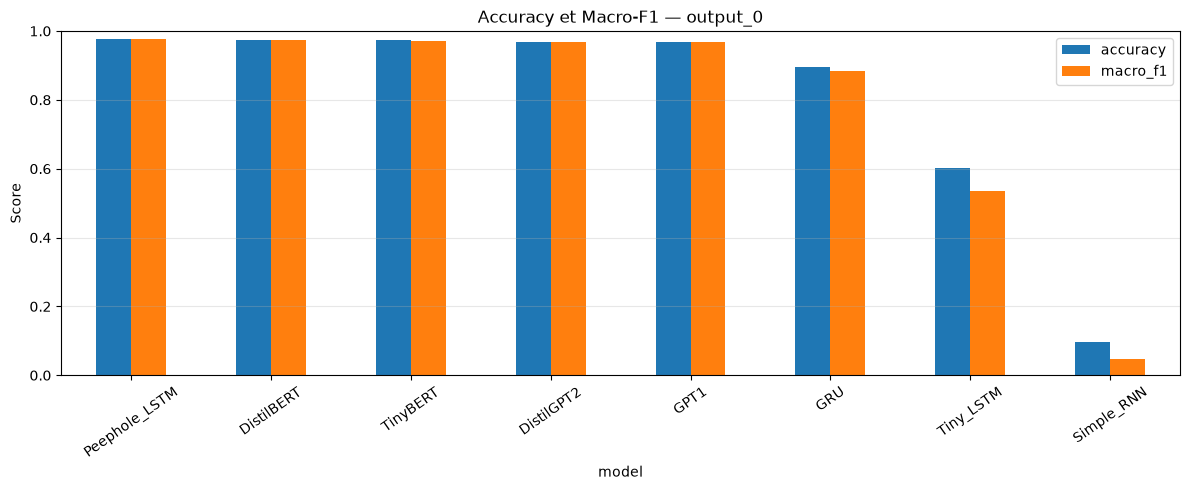

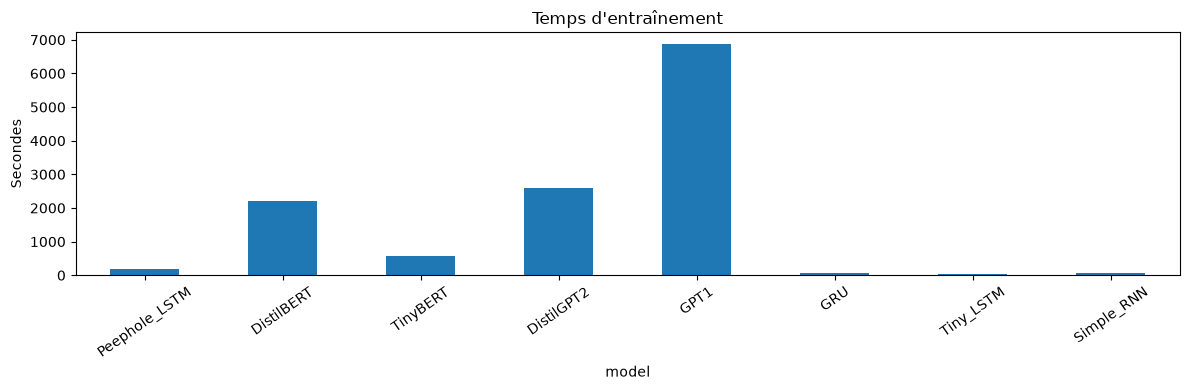

Meilleur modèle : Peephole_LSTM
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       175
           1       0.99      1.00      1.00       175
          10       1.00      0.77      0.87       175
          11       0.81      1.00      0.90       175
          12       1.00      1.00      1.00       175
          13       1.00      1.00      1.00       175
          14       1.00      1.00      1.00       175
          15       1.00      1.00      1.00       175
          16       1.00      1.00      1.00       175
          17       1.00      1.00      1.00       175
          18       1.00      1.00      1.00       175
          19       1.00      1.00      1.00       175
           2       0.94      0.95      0.95       175
          20       1.00      1.00      1.00       175
          21       1.00      1.00      1.00       175
          22       1.00      1.00      1.00       175
          23       1.00      1.00      1.00      

In [38]:
main_models = {
    "Simple_RNN", "GRU", "Peephole_LSTM", "Tiny_LSTM",
    "DistilGPT2", "GPT1", "DistilBERT", "TinyBERT"
}

# Garder uniquement les huit modèles de la comparaison initiale
comparison = (
    pd.DataFrame(results)
    .loc[lambda df: df["model"].isin(main_models)]
    .sort_values("macro_f1", ascending=False)
)
comparison.to_csv(RESULTS_DIR/"comparaison_8_modeles_output_0.csv",index=False)
display(comparison)

comparison.set_index("model")[["accuracy","macro_f1"]].plot(kind="bar",figsize=(12,5),ylim=(0,1),rot=35)
plt.title("Accuracy et Macro-F1 — output_0"); plt.ylabel("Score"); plt.grid(axis="y",alpha=.3); plt.tight_layout(); plt.show()

comparison.set_index("model")["training_time_sec"].plot(kind="bar",figsize=(12,4),rot=35)
plt.title("Temps d'entraînement"); plt.ylabel("Secondes"); plt.tight_layout(); plt.show()

best_name=comparison.iloc[0]["model"]
pred=pd.read_csv(RESULTS_DIR/f"{best_name}_predictions.csv")
print("Meilleur modèle :",best_name)
print(classification_report(pred.y_true,pred.y_pred,labels=list(range(N_CLASSES)),
                            target_names=encoder.classes_,zero_division=0))


## 11. Ajouter une nouvelle classe Dataset

In [22]:
class RDatasetAug(Dataset):
    def __init__(self, df, unk_prob=0.0):
        self.x = df.text.tolist()
        self.y = df.y.astype(int).tolist()
        self.unk_prob = unk_prob

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        ids = encode(self.x[i])

        # Remplacement aléatoire de quelques tokens par UNK
        if self.unk_prob > 0:
            ids = [
                UNK if token != PAD and token != UNK
                and random.random() < self.unk_prob
                else token
                for token in ids
            ]

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(self.y[i], dtype=torch.long)
        )


# Nouveau jeu d'entraînement avec augmentation
AUG_PROB = 0.05

tr_r_aug = DataLoader(
    RDatasetAug(train_df, unk_prob=AUG_PROB),
    batch_size=BATCH_RNN,
    shuffle=True
)

# Validation et test restent inchangés
va_r = DataLoader(
    RDatasetAug(val_df),
    batch_size=BATCH_RNN
)

te_r = DataLoader(
    RDatasetAug(test_df),
    batch_size=BATCH_RNN
)

print("Data Augmentation activée.")
print("Probabilité de remplacement :", AUG_PROB)
print("Nombre de logs d'entraînement :", len(train_df))


Data Augmentation activée.
Probabilité de remplacement : 0.05
Nombre de logs d'entraînement : 24500


## 12. Réentraîner Peephole LSTM

In [19]:
# Réinitialiser les graines pour faciliter la reproductibilité
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Créer un nouveau modèle, sans reprendre les anciens poids
peephole_aug = PeepholeClassifier()

# Entraînement avec Data Augmentation
peephole_aug, elapsed_aug, hist_aug = fit(
    peephole_aug,
    tr_r_aug,
    va_r,
    name="Peephole_LSTM_DataAug",
    epochs=EPOCHS_RNN,
    lr=LR_RNN
)

# Évaluation sur le test original
result_aug = record_result(
    "Peephole_LSTM_DataAug",
    peephole_aug,
    elapsed_aug,
    te_r,
    history=hist_aug
)


Peephole_LSTM_DataAug 1/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 1 | loss=1.4416 | val Macro-F1=0.9335


Peephole_LSTM_DataAug 2/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 2 | loss=0.2440 | val Macro-F1=0.9692


Peephole_LSTM_DataAug 3/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 3 | loss=0.1207 | val Macro-F1=0.9742


... (6 outputs left out)

Peephole_LSTM_DataAug 7/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 7 | loss=0.0646 | val Macro-F1=0.9761


Peephole_LSTM_DataAug 8/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 8 | loss=0.0631 | val Macro-F1=0.9761
Test : {'model': 'Peephole_LSTM_DataAug', 'accuracy': 0.9761904761904762, 'precision_macro': 0.9793246347093297, 'recall_macro': 0.9761904761904762, 'macro_f1': 0.9759695644992153, 'training_time_sec': 178.88, 'parameters': 3975838}


## 13. Vérifier la robustesse sur des logs perturbés

In [23]:
# Jeu de test artificiellement perturbé
te_r_corrupted = DataLoader(
    RDatasetAug(test_df, unk_prob=0.05),
    batch_size=BATCH_RNN,
    shuffle=False
)

# Évaluation du modèle augmenté
random.seed(SEED)
robust_metrics, _, _ = evaluate(
    peephole_aug,
    te_r_corrupted
)

print("Performances sur le test perturbé :")
print(robust_metrics)


Performances sur le test perturbé :
{'accuracy': 0.9706666666666667, 'precision_macro': 0.9736864780092401, 'recall_macro': 0.9706666666666667, 'macro_f1': 0.9704572765987174}


## 14. Comparaison avec le modèle initial

,Modèle,Test,accuracy,precision_macro,recall_macro,macro_f1
0,Initial,Normal,0.9775,0.9805,0.9775,0.9773
1,Data Augmentation,Normal,0.9762,0.9793,0.9762,0.9760
2,Initial,Perturbé,0.9657,0.9689,0.9657,0.9655
3,Data Augmentation,Perturbé,0.9707,0.9737,0.9707,0.9705


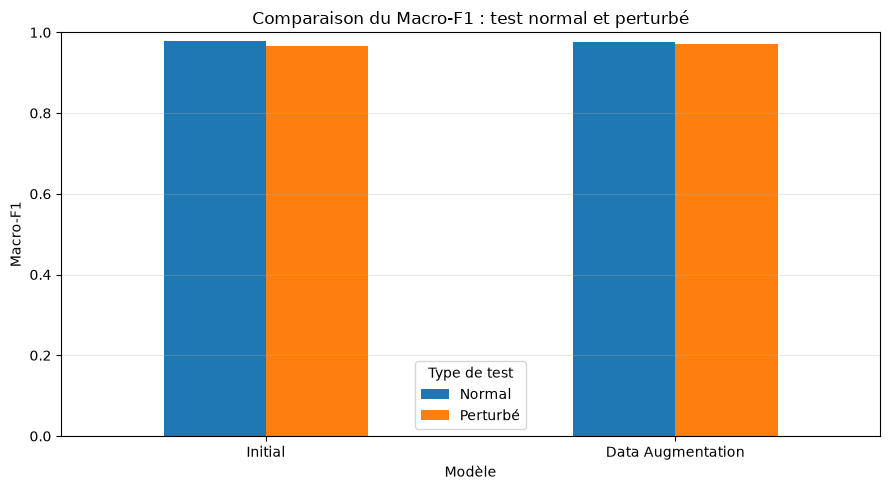

In [40]:

# Recharger le modèle initial depuis son meilleur checkpoint
peephole = PeepholeClassifier().to(DEVICE)
peephole.load_state_dict(torch.load(MODELS_DIR / "Peephole_LSTM.pt", map_location=DEVICE))

# 1. Modèle initial sur le test normal
initial_metrics, _, _ = evaluate(peephole, te_r)

# 2. Modèle augmenté sur le test normal
aug_normal_metrics, _, _ = evaluate(peephole_aug, te_r)

# 3. Modèle initial sur le test perturbé
random.seed(SEED)
initial_robust_metrics, _, _ = evaluate(peephole, te_r_corrupted)

# 4. Modèle augmenté sur le test perturbé
random.seed(SEED)
aug_robust_metrics, _, _ = evaluate(peephole_aug, te_r_corrupted)

comparison = pd.DataFrame([
    {"Modèle": "Initial", "Test": "Normal", **initial_metrics},
    {"Modèle": "Data Augmentation", "Test": "Normal", **aug_normal_metrics},
    {"Modèle": "Initial", "Test": "Perturbé", **initial_robust_metrics},
    {"Modèle": "Data Augmentation", "Test": "Perturbé", **aug_robust_metrics},
])

display(comparison.round(4))

macro_f1_plot = comparison.pivot(
    index="Modèle",
    columns="Test",
    values="macro_f1"
).reindex(["Initial", "Data Augmentation"])

ax = macro_f1_plot.plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0)
ax.set_title("Comparaison du Macro-F1 : test normal et perturbé")
ax.set_ylabel("Macro-F1")
ax.set_xlabel("Modèle")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Type de test")
plt.tight_layout()
plt.show()


## 15. Ajouter le modèle compatible avec FGSM

In [27]:
class PeepholeClassifierAdv(PeepholeClassifier):

    def forward_from_embeddings(self, z, x):
        b = x.size(0)

        h = torch.zeros(b, HIDDEN_DIM, device=x.device)
        c = torch.zeros_like(h)

        for t in range(z.size(1)):
            hn, cn = self.cell(z[:, t], (h, c))

            active = (x[:, t] != PAD).unsqueeze(1)
            h = torch.where(active, hn, h)
            c = torch.where(active, cn, c)

        return self.fc(self.drop(h))

    def forward(self, x):
        z = self.emb(x)
        return self.forward_from_embeddings(z, x)


## 16. Créer la fonction d'entraînement adversarial

In [28]:
def fit_adversarial(
    model,
    train_loader,
    val_loader,
    name,
    epochs,
    lr,
    epsilon=0.05
):
    model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr
    )

    loss_fn = nn.CrossEntropyLoss()

    best_f1 = -1
    best_state = None
    history = []

    start = time.time()

    for ep in range(1, epochs + 1):

        model.train()
        total_loss = 0

        for ids, labels in tqdm(
            train_loader,
            desc=f"{name} {ep}/{epochs}",
            leave=False
        ):
            ids = ids.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            # 1. Calcul des embeddings originaux
            embeddings = model.emb(ids)

            # 2. Prédiction sur les données originales
            logits_clean = model.forward_from_embeddings(
                embeddings, ids
            )

            loss_clean = loss_fn(logits_clean, labels)

            # 3. Calcul du gradient par rapport aux embeddings
            grad = torch.autograd.grad(
                loss_clean,
                embeddings,
                retain_graph=True
            )[0]

            # 4. Création de la perturbation FGSM
            mask = (ids != PAD).unsqueeze(-1)

            perturbation = epsilon * grad.sign()
            perturbation = perturbation * mask

            # 5. Nouvelle représentation perturbée
            adv_embeddings = model.emb(ids) + perturbation.detach()

            # 6. Prédiction sur les données adversariales
            logits_adv = model.forward_from_embeddings(
                adv_embeddings, ids
            )

            loss_adv = loss_fn(logits_adv, labels)

            # 7. Apprentissage sur les deux versions
            loss = 0.5 * (loss_clean + loss_adv)

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            total_loss += loss.item()

        # Évaluation sur la validation originale
        val_metrics, _, _ = evaluate(model, val_loader)

        avg_loss = total_loss / max(1, len(train_loader))

        history.append({
            "epoch": ep,
            "train_loss": avg_loss,
            **val_metrics
        })

        print(
            f"Epoch {ep} | loss={avg_loss:.4f} "
            f"| val Macro-F1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())

    if best_state is not None:
        model.load_state_dict(best_state)

    elapsed = time.time() - start

    torch.save(
        model.state_dict(),
        MODELS_DIR / f"{name}.pt"
    )

    return model, elapsed, pd.DataFrame(history)


## 17. Entraîner le nouveau modèle

In [29]:
# Reproductibilité
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Intensité de la perturbation
ADV_EPSILON = 0.05

# Création d'un nouveau modèle
peephole_adv = PeepholeClassifierAdv()

# Entraînement adversarial sur les données originales
peephole_adv, elapsed_adv, hist_adv = fit_adversarial(
    peephole_adv,
    tr_r,
    va_r,
    name="Peephole_LSTM_Adversarial",
    epochs=EPOCHS_RNN,
    lr=LR_RNN,
    epsilon=ADV_EPSILON
)

# Évaluation sur le test normal
result_adv = record_result(
    "Peephole_LSTM_Adversarial",
    peephole_adv,
    elapsed_adv,
    te_r,
    history=hist_adv
)


Peephole_LSTM_Adversarial 1/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 1 | loss=1.4529 | val Macro-F1=0.9269


Peephole_LSTM_Adversarial 2/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 2 | loss=0.2710 | val Macro-F1=0.9509


Peephole_LSTM_Adversarial 3/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 3 | loss=0.1527 | val Macro-F1=0.9694


... (6 outputs left out)

Peephole_LSTM_Adversarial 7/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 7 | loss=0.0543 | val Macro-F1=0.9747


Peephole_LSTM_Adversarial 8/8:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 8 | loss=0.0535 | val Macro-F1=0.9753
Test : {'model': 'Peephole_LSTM_Adversarial', 'accuracy': 0.9765714285714285, 'precision_macro': 0.9800589303881767, 'recall_macro': 0.9765714285714285, 'macro_f1': 0.9763421293110998, 'training_time_sec': 446.67, 'parameters': 3975838}


## 18. Évaluer la robustesse

In [30]:
random.seed(SEED)

adv_robust_metrics, _, _ = evaluate(
    peephole_adv,
    te_r_corrupted
)

print("Performances du modèle adversarial sur le test perturbé :")
print(adv_robust_metrics)


Performances du modèle adversarial sur le test perturbé :
{'accuracy': 0.9676190476190476, 'precision_macro': 0.9714449719081694, 'recall_macro': 0.9676190476190478, 'macro_f1': 0.9675387045554155}


,Modèle,Test,accuracy,precision_macro,recall_macro,macro_f1
0,Initial,Normal,0.9775,0.9805,0.9775,0.9773
1,Initial,Perturbé,0.9657,0.9689,0.9657,0.9655
2,Adversarial,Normal,0.9766,0.9801,0.9766,0.9763
3,Adversarial,Perturbé,0.9676,0.9714,0.9676,0.9675


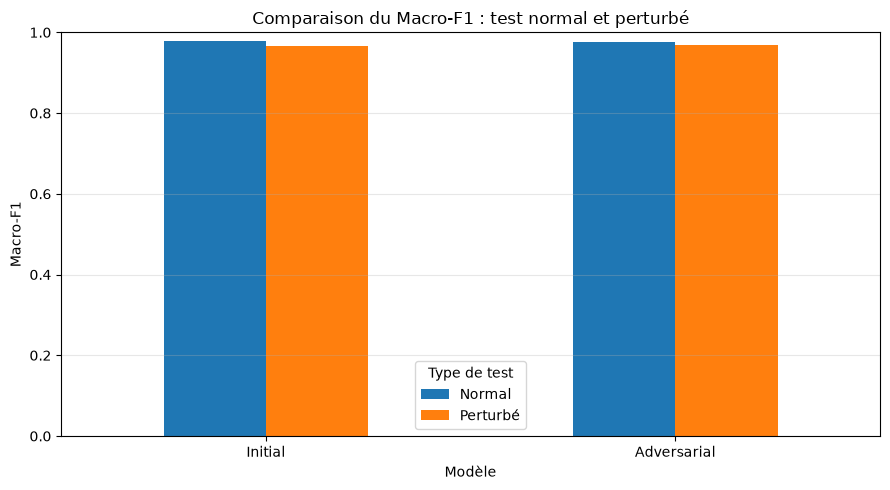

In [41]:
# Comparer les modèles initial et adversarial
initial_normal_metrics, _, _ = evaluate(peephole, te_r)
adv_normal_metrics, _, _ = evaluate(peephole_adv, te_r)

random.seed(SEED)
initial_robust_metrics, _, _ = evaluate(peephole, te_r_corrupted)

random.seed(SEED)
adv_robust_metrics, _, _ = evaluate(peephole_adv, te_r_corrupted)

comparison_initial_adv = pd.DataFrame([
    {"Modèle": "Initial", "Test": "Normal", **initial_normal_metrics},
    {"Modèle": "Initial", "Test": "Perturbé", **initial_robust_metrics},
    {"Modèle": "Adversarial", "Test": "Normal", **adv_normal_metrics},
    {"Modèle": "Adversarial", "Test": "Perturbé", **adv_robust_metrics},
])

display(comparison_initial_adv.round(4))

macro_f1_plot = comparison_initial_adv.pivot(
    index="Modèle",
    columns="Test",
    values="macro_f1"
).reindex(["Initial", "Adversarial"])

ax = macro_f1_plot.plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0)
ax.set_title("Comparaison du Macro-F1 : test normal et perturbé")
ax.set_ylabel("Macro-F1")
ax.set_xlabel("Modèle")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Type de test")
plt.tight_layout()
plt.show()


,Modèle,Test,accuracy,precision_macro,recall_macro,macro_f1
0,Initial,Normal,0.9775,0.9805,0.9775,0.9773
1,Initial,Perturbé,0.9657,0.9689,0.9657,0.9655
2,Data Augmentation,Normal,0.9762,0.9793,0.9762,0.9760
3,Data Augmentation,Perturbé,0.9707,0.9737,0.9707,0.9705
4,Adversarial,Normal,0.9766,0.9801,0.9766,0.9763
5,Adversarial,Perturbé,0.9676,0.9714,0.9676,0.9675


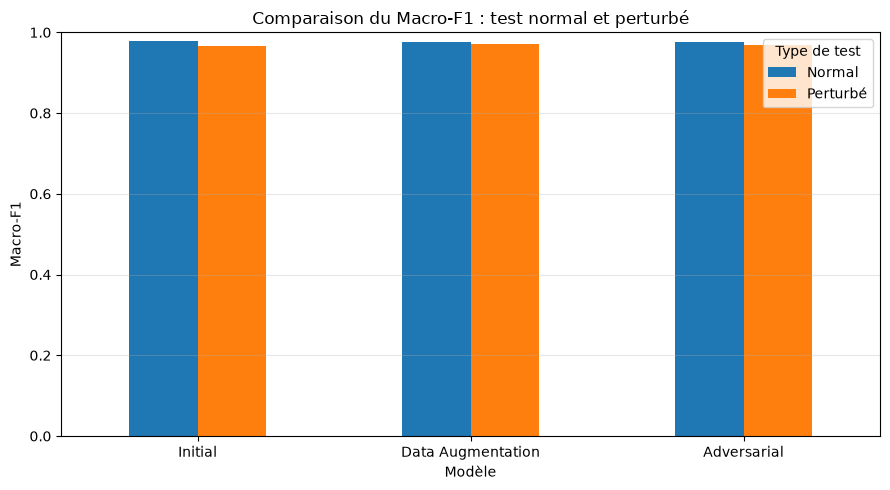

In [ ]:
# Comparer les modèles initial, augmenté et adversarial
initial_metrics, _, _ = evaluate(peephole, te_r)
aug_normal_metrics, _, _ = evaluate(peephole_aug, te_r)
adv_normal_metrics, _, _ = evaluate(peephole_adv, te_r)

# Réinitialiser la graine pour évaluer chaque modèle sur les mêmes perturbations
random.seed(SEED)
initial_robust_metrics, _, _ = evaluate(peephole, te_r_corrupted)

random.seed(SEED)
aug_robust_metrics, _, _ = evaluate(peephole_aug, te_r_corrupted)

random.seed(SEED)
adv_robust_metrics, _, _ = evaluate(peephole_adv, te_r_corrupted)

comparison_adv = pd.DataFrame([
    {"Modèle": "Initial", "Test": "Normal", **initial_metrics},
    {"Modèle": "Initial", "Test": "Perturbé", **initial_robust_metrics},
    {"Modèle": "Data Augmentation", "Test": "Normal", **aug_normal_metrics},
    {"Modèle": "Data Augmentation", "Test": "Perturbé", **aug_robust_metrics},
    {"Modèle": "Adversarial", "Test": "Normal", **adv_normal_metrics},
    {"Modèle": "Adversarial", "Test": "Perturbé", **adv_robust_metrics},
])

display(comparison_adv.round(4))

# Diagramme des scores Macro-F1 sur les tests normal et perturbé
macro_f1_plot = comparison_adv.pivot(
    index="Modèle",
    columns="Test",
    values="macro_f1"
).reindex(["Initial", "Data Augmentation", "Adversarial"])

ax = macro_f1_plot.plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0)
ax.set_title("Comparaison du Macro-F1 : test normal et perturbé")
ax.set_ylabel("Macro-F1")
ax.set_xlabel("Modèle")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Type de test")
plt.tight_layout()
plt.show()
